In [8]:

import pandas as pd
import glob

# Find your uploaded archaeological CSV
files = glob.glob("/content/ModelRunSamples*.csv")

print("Found files:", files)

# Load the dataset
df = pd.read_csv(files[0])

# Display the first five rows
df.head()


Found files: ['/content/ModelRunSamples_Presence&Absence - ModelRunSamples_Presence&Absence.csv (1).csv']


,x,y,type,Unnamed: 3,Unnamed: 4
0,-74.728041,5.210790,presence,NaN,NaN
1,-74.611260,5.205176,presence,NaN,NaN
2,-74.579819,5.192824,presence,NaN,NaN
3,-74.697723,5.190578,presence,NaN,NaN
4,-74.697723,5.190578,presence,NaN,NaN


In [9]:

print("Dataset shape:", df.shape)

print("\nLocation types:")
print(df["type"].value_counts())

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate coordinates:")
print(df.duplicated(subset=["x", "y"]).sum())


Dataset shape: (71650, 5)

Location types:
type
absence/pseudo-absence    66077
presence                   5571
Name: count, dtype: int64

Missing values:
x                 2
y                 2
type              2
Unnamed: 3    71650
Unnamed: 4    71648
dtype: int64

Duplicate coordinates:
2247


In [10]:

df_original = df.copy()

# Keep only the three columns we need
df_clean = df[["x", "y", "type"]].copy()

# Remove rows missing coordinates or labels
df_clean = df_clean.dropna(
    subset=["x", "y", "type"]
)

# Make sure coordinates are numeric
df_clean["x"] = pd.to_numeric(
    df_clean["x"], errors="coerce"
)
df_clean["y"] = pd.to_numeric(
    df_clean["y"], errors="coerce"
)

df_clean = df_clean.dropna(
    subset=["x", "y"]
)

# Check results
print("Cleaned shape:", df_clean.shape)
print(df_clean["type"].value_counts())


Cleaned shape: (71648, 3)
type
absence/pseudo-absence    66077
presence                   5571
Name: count, dtype: int64


In [11]:

# Count duplicated coordinates
print("Duplicate coordinates:",
      df_clean.duplicated(subset=["x", "y"]).sum())

# Find coordinates associated with different labels
conflicts = (
    df_clean.groupby(["x", "y"])["type"]
    .nunique()
)

conflicts = conflicts[conflicts > 1]

print("Coordinates with conflicting labels:",
      len(conflicts))

# Show some duplicated records
duplicates = df_clean[
    df_clean.duplicated(
        subset=["x", "y"], keep=False
    )
].sort_values(["x", "y"])

display(duplicates.head(20))


Duplicate coordinates: 2246
Coordinates with conflicting labels: 0


,x,y,type
5379,-76.369949,1.914337,presence
5380,-76.369949,1.914337,presence
5554,-76.329572,1.789839,presence
5555,-76.329572,1.789839,presence
5509,-76.303776,1.880688,presence
5510,-76.303776,1.880688,presence
5511,-76.303776,1.880688,presence
5518,-76.302652,1.879565,presence
5519,-76.302652,1.879565,presence
5520,-76.302652,1.879565,presence


In [12]:

# Keep one record per geographical location
df_clean = df_clean.drop_duplicates(
    subset=["x", "y"]
).reset_index(drop=True)

print("Dataset after cleaning:", df_clean.shape)

print("\nLocation types:")
print(df_clean["type"].value_counts())

print("\nRemaining duplicate coordinates:")
print(df_clean.duplicated(subset=["x", "y"]).sum())


Dataset after cleaning: (69402, 3)

Location types:
type
absence/pseudo-absence    66077
presence                   3325
Name: count, dtype: int64

Remaining duplicate coordinates:
0


In [13]:

# Original presence records
presence = df_original[
    df_original["type"] == "presence"
].copy()

# Count how often each coordinate appears
counts = (
    presence.groupby(["x", "y"])
    .size()
    .value_counts()
    .sort_index()
)

print("Number of repetitions:")
print(counts)

print("\nUnique presence locations:")
print(
    presence.drop_duplicates(
        subset=["x", "y"]
    ).shape[0]
)


Number of repetitions:
1     2255
2      666
3      168
4       98
5       44
6       23
7       16
8       13
9        9
10       8
11       6
12       6
13       3
14       2
15       1
16       1
17       2
20       2
21       1
22       1
Name: count, dtype: int64

Unique presence locations:
3325


In [14]:

!pip uninstall -y elevatr


In [15]:

!pip check


ipython 7.34.0 requires jedi, which is not installed.


In [16]:

import pandas as pd
import numpy as np
import rasterio

print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Rasterio:", rasterio.__version__)

print("Dataset:", df_clean.shape)


Pandas: 2.2.3
NumPy: 2.4.6
Rasterio: 1.5.2
Dataset: (69402, 3)


In [17]:

!pip -q install rio-tiler


In [18]:

print("Longitude range:")
print(df_clean["x"].min(), "to", df_clean["x"].max())

print("\nLatitude range:")
print(df_clean["y"].min(), "to", df_clean["y"].max())

print("\nArchaeological labels:")
print(df_clean["type"].value_counts())


Longitude range:
-76.4718958 to -67.78409717

Latitude range:
-3.846206532 to 12.23530063

Archaeological labels:
type
absence/pseudo-absence    66077
presence                   3325
Name: count, dtype: int64


In [19]:

# Step 1: Create df_test from our cleaned dataset
df_test = df_clean.copy()

# Step 2: Create geographical cells
df_test["lon_cell"] = (df_test["x"] * 2).floordiv(1) / 2
df_test["lat_cell"] = (df_test["y"] * 2).floordiv(1) / 2

# Step 3: Select our experimental region
region = df_test[
    (df_test["lon_cell"] == -73.0) &
    (df_test["lat_cell"] == 5.5)
].copy()

# Step 4: Check the results
print("Total locations:", len(region))
print(region["type"].value_counts())

display(region.head())


Total locations: 643
type
presence                  488
absence/pseudo-absence    155
Name: count, dtype: int64


,x,y,type,lon_cell,lat_cell
1635,-72.946822,5.916206,presence,-73.0,5.5
1640,-72.989447,5.847786,presence,-73.0,5.5
1641,-72.995052,5.839937,presence,-73.0,5.5
1642,-72.876163,5.837695,presence,-73.0,5.5
1645,-72.995052,5.835452,presence,-73.0,5.5


In [20]:

import pandas as pd
import glob

# Find the uploaded archaeological dataset
files = glob.glob("/content/ModelRunSamples*.csv")

if not files:
    raise FileNotFoundError(
        "CSV not found. Upload ModelRunSamples_Presence&Absence.csv first."
    )

# Load the original dataset
df = pd.read_csv(files[0])

# Keep the three relevant columns
df_clean = df[["x", "y", "type"]].copy()

# Convert coordinates into numbers
df_clean["x"] = pd.to_numeric(df_clean["x"], errors="coerce")
df_clean["y"] = pd.to_numeric(df_clean["y"], errors="coerce")

# Remove missing values
df_clean = df_clean.dropna(subset=["x", "y", "type"])

# Remove duplicate coordinate pairs
df_clean = df_clean.drop_duplicates(
    subset=["x", "y"]
).reset_index(drop=True)

print("Cleaned dataset:", df_clean.shape)
print(df_clean["type"].value_counts())


Cleaned dataset: (69402, 3)
type
absence/pseudo-absence    66077
presence                   3325
Name: count, dtype: int64


In [21]:

import requests
import math
import io
import numpy as np
from PIL import Image

# Function to convert longitude and latitude to tile coordinates
def get_tile_coordinates(lon, lat, zoom=10):
    lat_rad = math.radians(lat)
    n = 2 ** zoom

    x = int((lon + 180.0) / 360.0 * n)
    y = int(
        (1.0 - math.asinh(math.tan(lat_rad)) / math.pi)
        / 2.0 * n
    )

    return x, y

# Test using the first archaeological location
lon = region.iloc[0]["x"]
lat = region.iloc[0]["y"]

tile_x, tile_y = get_tile_coordinates(lon, lat)

print("Longitude:", lon)
print("Latitude:", lat)
print("Tile X:", tile_x)
print("Tile Y:", tile_y)


Longitude: -72.94682208
Latitude: 5.916205964
Tile X: 304
Tile Y: 495


Tile downloaded successfully!
Image size: (256, 256)


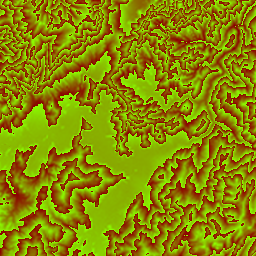

In [22]:

zoom = 10

url = (
    f"https://s3.amazonaws.com/elevation-tiles-prod/"
    f"terrarium/{zoom}/{tile_x}/{tile_y}.png"
)

response = requests.get(url, timeout=30)
response.raise_for_status()

tile_image = Image.open(io.BytesIO(response.content)).convert("RGB")

print("Tile downloaded successfully!")
print("Image size:", tile_image.size)

display(tile_image)


In [23]:

# Find the pixel corresponding to our archaeological coordinate
n = 2 ** zoom

x_float = (lon + 180) / 360 * n

y_float = (
    1 - math.asinh(math.tan(math.radians(lat))) / math.pi
) / 2 * n

pixel_x = int((x_float - tile_x) * 256)
pixel_y = int((y_float - tile_y) * 256)

# Read the pixel's RGB values
R, G, B = tile_image.getpixel((pixel_x, pixel_y))

# Convert RGB into elevation in meters
elevation = 256 * R + G + B / 256 - 32768

print("Archaeological coordinate:", lon, lat)
print("RGB values:", R, G, B)
print("Elevation:", round(elevation, 2), "meters")


Archaeological coordinate: -72.94682208 5.916205964
RGB values: 139 40 0
Elevation: 2856.0 meters


In [24]:

import requests
import math
import io
import numpy as np
from PIL import Image

# Cache downloaded tiles so we don't download the same tile repeatedly
tile_cache = {}

def get_elevation(lon, lat, zoom=10):
    n = 2 ** zoom

    # Convert longitude and latitude into tile coordinates
    x_float = (lon + 180.0) / 360.0 * n

    y_float = (
        1.0 - math.asinh(math.tan(math.radians(lat))) / math.pi
    ) / 2.0 * n

    tile_x = int(x_float)
    tile_y = int(y_float)

    # Download tile only if it hasn't been downloaded already
    tile_key = (zoom, tile_x, tile_y)

    if tile_key not in tile_cache:
        url = (
            "https://s3.amazonaws.com/elevation-tiles-prod/"
            f"terrarium/{zoom}/{tile_x}/{tile_y}.png"
        )

        response = requests.get(url, timeout=30)
        response.raise_for_status()

        image = Image.open(
            io.BytesIO(response.content)
        ).convert("RGB")

        tile_cache[tile_key] = image

    # Find the correct pixel
    image = tile_cache[tile_key]
    width, height = image.size

    pixel_x = min(width - 1, max(0, int((x_float - tile_x) * width)))
    pixel_y = min(height - 1, max(0, int((y_float - tile_y) * height)))

    R, G, B = image.getpixel((pixel_x, pixel_y))

    # Decode Terrarium elevation
    elevation = 256 * R + G + B / 256 - 32768

    return elevation


# Create a new dataset
region_ml = region.copy()

# Extract elevation for every archaeological location
region_ml["elevation"] = [
    get_elevation(lon, lat)
    for lon, lat in zip(region_ml["x"], region_ml["y"])
]

print("Elevation extraction completed!")
print("Total locations:", len(region_ml))

display(region_ml.head())


Elevation extraction completed!
Total locations: 643


,x,y,type,lon_cell,lat_cell,elevation
1635,-72.946822,5.916206,presence,-73.0,5.5,2856.0
1640,-72.989447,5.847786,presence,-73.0,5.5,2716.0
1641,-72.995052,5.839937,presence,-73.0,5.5,2734.0
1642,-72.876163,5.837695,presence,-73.0,5.5,2635.0
1645,-72.995052,5.835452,presence,-73.0,5.5,2738.0


In [25]:

print(region_ml["elevation"].describe())

print(
    "Missing elevation values:",
    region_ml["elevation"].isna().sum()
)

print(
    "Number of downloaded tiles:",
    len(tile_cache)
)


count     643.000000
mean     2546.111975
std       101.032520
min      2468.000000
25%      2483.000000
50%      2493.000000
75%      2570.500000
max      2922.000000
Name: elevation, dtype: float64
Missing elevation values: 0
Number of downloaded tiles: 2


In [26]:

import math
import numpy as np

def get_slope(lon, lat, distance=100):
    """
    Estimate terrain slope in degrees using
    elevation differences over approximately
    100 meters in each direction.
    """

    # Convert 100 meters to latitude degrees
    delta_lat = distance / 111320

    # Convert 100 meters to longitude degrees
    delta_lon = distance / (
        111320 * math.cos(math.radians(lat))
    )

    # Get elevation at four surrounding points
    east = get_elevation(lon + delta_lon, lat)
    west = get_elevation(lon - delta_lon, lat)

    north = get_elevation(lon, lat + delta_lat)
    south = get_elevation(lon, lat - delta_lat)

    # Estimate elevation change per meter
    dz_dx = (east - west) / (2 * distance)
    dz_dy = (north - south) / (2 * distance)

    # Calculate slope in degrees
    slope_radians = math.atan(
        math.sqrt(dz_dx**2 + dz_dy**2)
    )

    return math.degrees(slope_radians)


# Test the function on our first location
test_lon = region_ml.iloc[0]["x"]
test_lat = region_ml.iloc[0]["y"]

print(
    "Estimated slope:",
    round(get_slope(test_lon, test_lat), 2),
    "degrees"
)


Estimated slope: 11.59 degrees


In [27]:

region_ml["slope"] = [
    get_slope(lon, lat)
    for lon, lat in zip(region_ml["x"], region_ml["y"])
]

print("Slope extraction completed!")

print(region_ml[["elevation", "slope"]].describe())

display(
    region_ml[["x", "y", "type", "elevation", "slope"]].head()
)


Slope extraction completed!
         elevation       slope
count   643.000000  643.000000
mean   2546.111975    4.602954
std     101.032520    5.249398
min    2468.000000    0.000000
25%    2483.000000    0.640560
50%    2493.000000    1.669972
75%    2570.500000    7.906560
max    2922.000000   29.470291


,x,y,type,elevation,slope
1635,-72.946822,5.916206,presence,2856.0,11.588478
1640,-72.989447,5.847786,presence,2716.0,14.538041
1641,-72.995052,5.839937,presence,2734.0,16.721129
1642,-72.876163,5.837695,presence,2635.0,4.014341
1645,-72.995052,5.835452,presence,2738.0,13.456164


In [28]:

from google.colab import files

region_ml.to_csv(
    "archaeological_ml_features.csv",
    index=False
)

files.download("archaeological_ml_features.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [29]:

import pandas as pd
import numpy as np

# Keep the variables needed for ML
ml_data = region_ml[
    ["x", "y", "elevation", "slope", "type"]
].copy()

# Convert archaeological labels into numbers
ml_data["target"] = (
    ml_data["type"] == "presence"
).astype(int)

print("Dataset shape:", ml_data.shape)
print("\nTarget distribution:")
print(ml_data["target"].value_counts())

display(ml_data.head())


Dataset shape: (643, 6)

Target distribution:
target
1    488
0    155
Name: count, dtype: int64


,x,y,elevation,slope,type,target
1635,-72.946822,5.916206,2856.0,11.588478,presence,1
1640,-72.989447,5.847786,2716.0,14.538041,presence,1
1641,-72.995052,5.839937,2734.0,16.721129,presence,1
1642,-72.876163,5.837695,2635.0,4.014341,presence,1
1645,-72.995052,5.835452,2738.0,13.456164,presence,1


In [30]:

# Create smaller geographical blocks
block_size = 0.1

ml_data["block_x"] = np.floor(
    ml_data["x"] / block_size
).astype(int)

ml_data["block_y"] = np.floor(
    ml_data["y"] / block_size
).astype(int)

ml_data["spatial_group"] = (
    ml_data["block_x"].astype(str) + "_" +
    ml_data["block_y"].astype(str)
)

print(
    "Number of geographical groups:",
    ml_data["spatial_group"].nunique()
)

print(
    "Groups containing presence/background:"
)

display(
    pd.crosstab(
        ml_data["spatial_group"],
        ml_data["target"]
    ).head(10)
)


Number of geographical groups: 6
Groups containing presence/background:


target,0,1
spatial_group,,
-729_57,0,6
-729_58,0,1
-730_56,129,232
-730_57,26,239
-730_58,0,9
-730_59,0,1


In [31]:

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    average_precision_score
)

X = ml_data[["elevation", "slope"]]
y = ml_data["target"]
groups = ml_data["spatial_group"]

splitter = GroupShuffleSplit(
    n_splits=100,
    test_size=0.25,
    random_state=42
)

# Find a split containing both classes
selected_split = None

for train_idx, test_idx in splitter.split(X, y, groups):
    if (
        y.iloc[train_idx].nunique() == 2
        and y.iloc[test_idx].nunique() == 2
    ):
        selected_split = (train_idx, test_idx)
        break

if selected_split is None:
    raise ValueError(
        "Could not find a spatial split containing both classes."
    )

train_idx, test_idx = selected_split

X_train = X.iloc[train_idx]
X_test = X.iloc[test_idx]

y_train = y.iloc[train_idx]
y_test = y.iloc[test_idx]

model = RandomForestClassifier(
    n_estimators=200,
    class_weight="balanced",
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1
)

model.fit(X_train, y_train)

# Predictions
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

print("Training locations:", len(X_train))
print("Testing locations:", len(X_test))

print("\nClassification report:")
print(classification_report(y_test, y_pred, zero_division=0))

print("ROC-AUC:", round(roc_auc_score(y_test, y_prob), 3))
print(
    "Average precision:",
    round(average_precision_score(y_test, y_prob), 3)
)

print("\nConfusion matrix:")
print(confusion_matrix(y_test, y_pred))


Training locations: 372
Testing locations: 271

Classification report:
              precision    recall  f1-score   support

           0       0.18      0.81      0.29        26
           1       0.97      0.61      0.75       245

    accuracy                           0.63       271
   macro avg       0.57      0.71      0.52       271
weighted avg       0.89      0.63      0.70       271

ROC-AUC: 0.727
Average precision: 0.962

Confusion matrix:
[[ 21   5]
 [ 96 149]]


Feature importance:
elevation    0.705033
slope        0.294967
dtype: float64


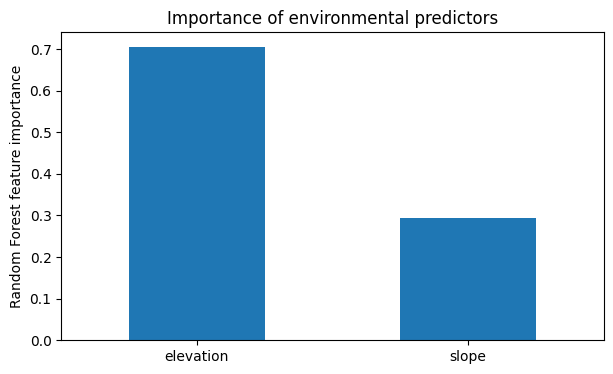

In [32]:

import pandas as pd
import matplotlib.pyplot as plt

importance = pd.Series(
    model.feature_importances_,
    index=X_train.columns
).sort_values(ascending=False)

print("Feature importance:")
print(importance)

plt.figure(figsize=(7, 4))
importance.plot(kind="bar")
plt.ylabel("Random Forest feature importance")
plt.title("Importance of environmental predictors")
plt.xticks(rotation=0)
plt.show()


In [33]:

from sklearn.model_selection import GroupShuffleSplit
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score
import numpy as np
import pandas as pd

splitter = GroupShuffleSplit(
    n_splits=30,
    test_size=0.25,
    random_state=42
)

results = []

for train_idx, test_idx in splitter.split(X, y, groups):

    y_train_cv = y.iloc[train_idx]
    y_test_cv = y.iloc[test_idx]

    # Both classes must appear in training and testing
    if y_train_cv.nunique() < 2 or y_test_cv.nunique() < 2:
        continue

    rf = RandomForestClassifier(
        n_estimators=200,
        class_weight="balanced",
        min_samples_leaf=5,
        random_state=42,
        n_jobs=-1
    )

    rf.fit(X.iloc[train_idx], y_train_cv)

    probabilities = rf.predict_proba(
        X.iloc[test_idx]
    )[:, 1]

    auc = roc_auc_score(y_test_cv, probabilities)

    results.append({
        "ROC_AUC": auc,
        "test_locations": len(test_idx),
        "test_presence_rate": y_test_cv.mean()
    })

results_df = pd.DataFrame(results)

print("Valid spatial splits:", len(results_df))
print("\nROC-AUC results:")
print(results_df["ROC_AUC"].describe())

print("\nAverage test presence rate:")
print(results_df["test_presence_rate"].mean())


Valid spatial splits: 17

ROC-AUC results:
count    17.000000
mean      0.801762
std       0.073603
min       0.724359
25%       0.727473
50%       0.866903
75%       0.866953
max       0.876194
Name: ROC_AUC, dtype: float64

Average test presence rate:
0.7674147082590111


In [34]:
for name in ["X_train", "X_test", "y_train", "y_test"]:
    print(name, "exists:", name in globals())

X_train exists: True
X_test exists: True
y_train exists: True
y_test exists: True


In [35]:

from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    balanced_accuracy_score
)

# Create the Logistic Regression model
lr_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=42
    )
)

# Train using the SAME training data
lr_model.fit(X_train, y_train)

# Make predictions using the SAME test data
lr_pred = lr_model.predict(X_test)
lr_prob = lr_model.predict_proba(X_test)[:, 1]

# Evaluate performance
print("LOGISTIC REGRESSION RESULTS")
print("\nClassification report:")
print(classification_report(y_test, lr_pred, zero_division=0))

print("ROC-AUC:", round(roc_auc_score(y_test, lr_prob), 3))
print("Balanced accuracy:",
      round(balanced_accuracy_score(y_test, lr_pred), 3))

print("\nConfusion matrix:")
print(confusion_matrix(y_test, lr_pred))


LOGISTIC REGRESSION RESULTS

Classification report:
              precision    recall  f1-score   support

           0       0.16      0.81      0.27        26
           1       0.96      0.56      0.70       245

    accuracy                           0.58       271
   macro avg       0.56      0.68      0.49       271
weighted avg       0.89      0.58      0.66       271

ROC-AUC: 0.695
Balanced accuracy: 0.681

Confusion matrix:
[[ 21   5]
 [109 136]]


In [36]:

from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    balanced_accuracy_score
)

# Create Decision Tree model
dt_model = DecisionTreeClassifier(
    max_depth=5,
    min_samples_leaf=5,
    class_weight="balanced",
    random_state=42
)

# Train the model
dt_model.fit(X_train, y_train)

# Make predictions
dt_pred = dt_model.predict(X_test)
dt_prob = dt_model.predict_proba(X_test)[:, 1]

# Evaluate
print("DECISION TREE RESULTS")
print(classification_report(y_test, dt_pred, zero_division=0))
print("ROC-AUC:", round(roc_auc_score(y_test, dt_prob), 3))
print("Balanced accuracy:",
      round(balanced_accuracy_score(y_test, dt_pred), 3))
print("Confusion matrix:")
print(confusion_matrix(y_test, dt_pred))


DECISION TREE RESULTS
              precision    recall  f1-score   support

           0       0.17      0.81      0.29        26
           1       0.97      0.60      0.74       245

    accuracy                           0.62       271
   macro avg       0.57      0.70      0.51       271
weighted avg       0.89      0.62      0.69       271

ROC-AUC: 0.711
Balanced accuracy: 0.702
Confusion matrix:
[[ 21   5]
 [ 99 146]]


In [37]:

from xgboost import XGBClassifier
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    balanced_accuracy_score
)

# Create XGBoost model
xgb_model = XGBClassifier(
    n_estimators=200,
    max_depth=3,
    learning_rate=0.05,
    random_state=42,
    eval_metric="logloss"
)

# Train the model
xgb_model.fit(X_train, y_train)

# Make predictions
xgb_pred = xgb_model.predict(X_test)
xgb_prob = xgb_model.predict_proba(X_test)[:, 1]

# Evaluate
print("XGBOOST RESULTS")
print(classification_report(y_test, xgb_pred, zero_division=0))
print("ROC-AUC:", round(roc_auc_score(y_test, xgb_prob), 3))
print("Balanced accuracy:",
      round(balanced_accuracy_score(y_test, xgb_pred), 3))
print("Confusion matrix:")
print(confusion_matrix(y_test, xgb_pred))


XGBOOST RESULTS
              precision    recall  f1-score   support

           0       0.17      0.73      0.28        26
           1       0.96      0.62      0.75       245

    accuracy                           0.63       271
   macro avg       0.56      0.68      0.51       271
weighted avg       0.88      0.63      0.71       271

ROC-AUC: 0.723
Balanced accuracy: 0.676
Confusion matrix:
[[ 19   7]
 [ 93 152]]


In [38]:

from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    balanced_accuracy_score
)

# Create SVM model
svm_model = make_pipeline(
    StandardScaler(),
    SVC(
        kernel="rbf",
        class_weight="balanced",
        probability=True,
        random_state=42
    )
)

# Train the model
svm_model.fit(X_train, y_train)

# Make predictions
svm_pred = svm_model.predict(X_test)
svm_prob = svm_model.predict_proba(X_test)[:, 1]

# Evaluate
print("SVM RESULTS")
print(classification_report(y_test, svm_pred, zero_division=0))
print("ROC-AUC:", round(roc_auc_score(y_test, svm_prob), 3))
print("Balanced accuracy:",
      round(balanced_accuracy_score(y_test, svm_pred), 3))
print("Confusion matrix:")
print(confusion_matrix(y_test, svm_pred))


SVM RESULTS
              precision    recall  f1-score   support

           0       0.16      0.73      0.26        26
           1       0.95      0.60      0.73       245

    accuracy                           0.61       271
   macro avg       0.56      0.66      0.50       271
weighted avg       0.88      0.61      0.69       271

ROC-AUC: 0.621
Balanced accuracy: 0.663
Confusion matrix:
[[ 19   7]
 [ 99 146]]


In [41]:

from sklearn.ensemble import RandomForestClassifier

# Create Random Forest with the original settings
rf_model = RandomForestClassifier(
    n_estimators=200,
    class_weight="balanced",
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1
)

# Train using the SAME data as the other four models
rf_model.fit(X_train, y_train)

print("Random Forest is ready!")


Random Forest is ready!


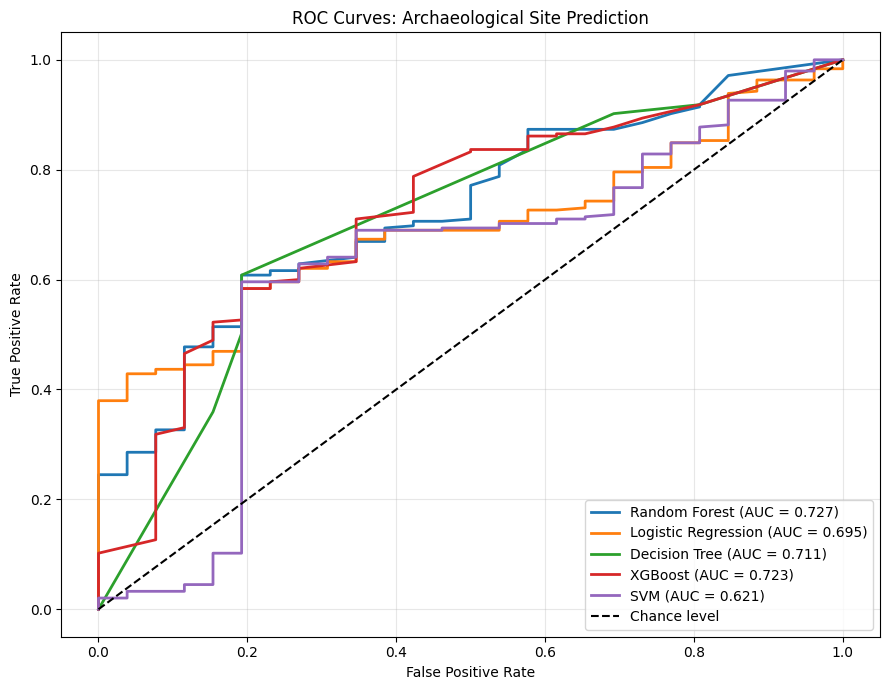

In [42]:

import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score

# Store the predicted probabilities from all five models
models = {
    "Random Forest": rf_model,
    "Logistic Regression": lr_model,
    "Decision Tree": dt_model,
    "XGBoost": xgb_model,
    "SVM": svm_model
}

plt.figure(figsize=(9, 7))

for name, model in models.items():
    probabilities = model.predict_proba(X_test)[:, 1]

    fpr, tpr, thresholds = roc_curve(
        y_test, probabilities
    )

    auc = roc_auc_score(y_test, probabilities)

    plt.plot(
        fpr, tpr,
        linewidth=2,
        label=f"{name} (AUC = {auc:.3f})"
    )

# Reference line for chance-level discrimination
plt.plot([0, 1], [0, 1], "k--", label="Chance level")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves: Archaeological Site Prediction")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig("archaeological_roc_comparison.png", dpi=300)
plt.show()


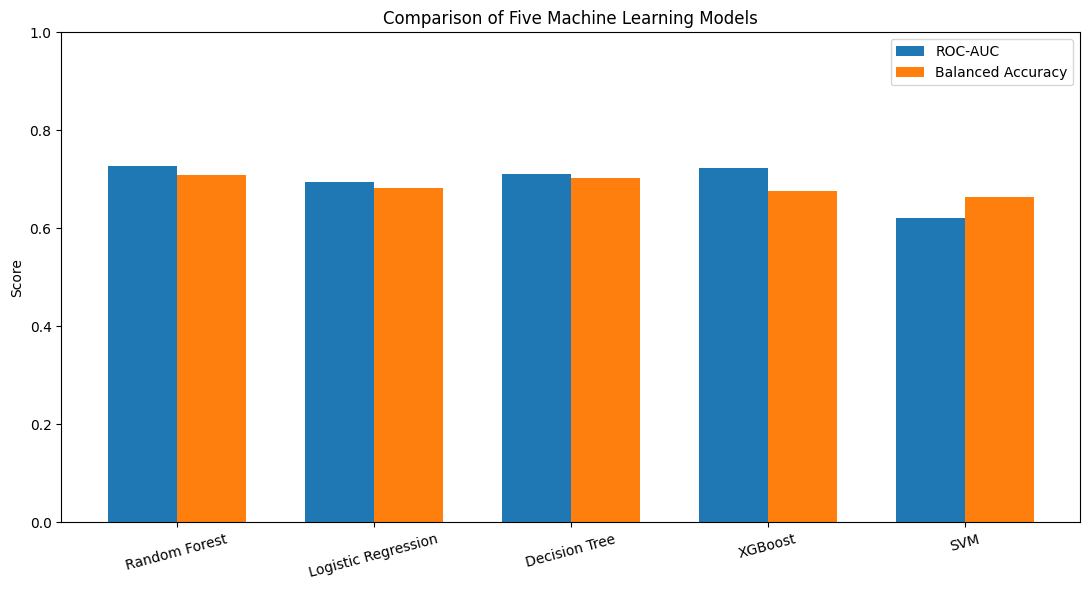

In [43]:

import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import roc_auc_score, balanced_accuracy_score

# Evaluate the models using the same test data
names = []
auc_scores = []
balanced_scores = []

for name, model in models.items():
    predictions = model.predict(X_test)
    probabilities = model.predict_proba(X_test)[:, 1]

    names.append(name)
    auc_scores.append(roc_auc_score(y_test, probabilities))
    balanced_scores.append(
        balanced_accuracy_score(y_test, predictions)
    )

x = np.arange(len(names))
width = 0.35

plt.figure(figsize=(11, 6))

plt.bar(x - width/2, auc_scores, width, label="ROC-AUC")
plt.bar(x + width/2, balanced_scores, width,
        label="Balanced Accuracy")

plt.xticks(x, names, rotation=15)
plt.ylabel("Score")
plt.ylim(0, 1)
plt.title("Comparison of Five Machine Learning Models")
plt.legend()
plt.tight_layout()

plt.savefig("model_performance_comparison.png", dpi=300)
plt.show()


In [ ]:

# Create a copy for visualization
map_data = ml_data.copy()

# Predict model scores for all locations
features = map_data[["elevation", "slope"]]

map_data["suitability_score"] = model.predict_proba(
    features
)[:, 1]

print("Prediction scores calculated!")

display(
    map_data[
        ["x", "y", "type", "elevation",
         "slope", "suitability_score"]
    ].head()
)


Prediction scores calculated!


,x,y,type,elevation,slope,suitability_score
1635,-72.946822,5.916206,presence,2856.0,11.588478,1.000000
1640,-72.989447,5.847786,presence,2716.0,14.538041,1.000000
1641,-72.995052,5.839937,presence,2734.0,16.721129,1.000000
1642,-72.876163,5.837695,presence,2635.0,4.014341,0.966682
1645,-72.995052,5.835452,presence,2738.0,13.456164,1.000000


In [ ]:

!pip -q install folium


In [ ]:

import folium
from branca.colormap import linear

# Find the geographical center of our dataset
center_lat = map_data["y"].mean()
center_lon = map_data["x"].mean()

# Create a map
m = folium.Map(
    location=[center_lat, center_lon],
    zoom_start=11,
    tiles="OpenStreetMap"
)

# Color scale: low score to high score
colormap = linear.YlOrRd_09.scale(0, 1)
colormap.caption = "Random Forest archaeological suitability score"

# Add every location to the map
for _, row in map_data.iterrows():

    score = float(row["suitability_score"])

    folium.CircleMarker(
        location=[row["y"], row["x"]],
        radius=4,
        color=colormap(score),
        fill=True,
        fill_color=colormap(score),
        fill_opacity=0.75,
        weight=1,
        popup=(
            f"Label: {row['type']}"
            f"<br>Elevation: {row['elevation']:.1f} m"
            f"<br>Slope: {row['slope']:.2f}°"
            f"<br>Suitability score: {score:.3f}"
        )
    ).add_to(m)

colormap.add_to(m)

display(m)


In [ ]:

import folium
from branca.colormap import linear

# Create a new map with a different background
m = folium.Map(
    location=[
        map_data["y"].mean(),
        map_data["x"].mean()
    ],
    zoom_start=11,
    tiles="CartoDB positron"
)

# Create the color scale
colormap = linear.YlOrRd_09.scale(0, 1)
colormap.caption = "Random Forest suitability score"

# Add our 643 archaeological locations
for _, row in map_data.iterrows():

    score = float(row["suitability_score"])

    folium.CircleMarker(
        location=[row["y"], row["x"]],
        radius=4,
        color=colormap(score),
        fill=True,
        fill_color=colormap(score),
        fill_opacity=0.8,
        weight=1,
        popup=(
            f"Label: {row['type']}"
            f"<br>Elevation: {row['elevation']:.1f} m"
            f"<br>Slope: {row['slope']:.2f}°"
            f"<br>Suitability score: {score:.3f}"
        )
    ).add_to(m)

colormap.add_to(m)

display(m)


/usr/local/lib/python3.13/dist-packages/folium/raster_layers.py:130: UserWarning: CartoDB tiles now require an API key. Please provide one to continue using the tiles. You can request the key at https://carto.com/basemaps/apikey/.
  tiles = tiles.build_url(fill_subdomain=False, scale_factor="{r}")  # type: ignore


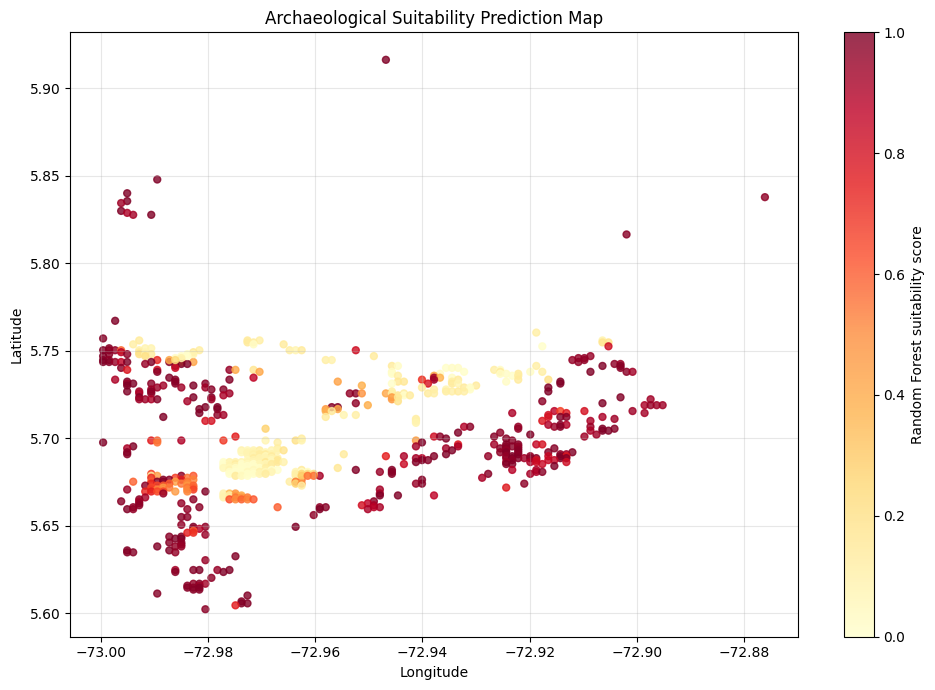

In [ ]:

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 7))

scatter = plt.scatter(
    map_data["x"],
    map_data["y"],
    c=map_data["suitability_score"],
    cmap="YlOrRd",
    s=25,
    alpha=0.8,
    vmin=0,
    vmax=1
)

plt.colorbar(
    scatter,
    label="Random Forest suitability score"
)

plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Archaeological Suitability Prediction Map")

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


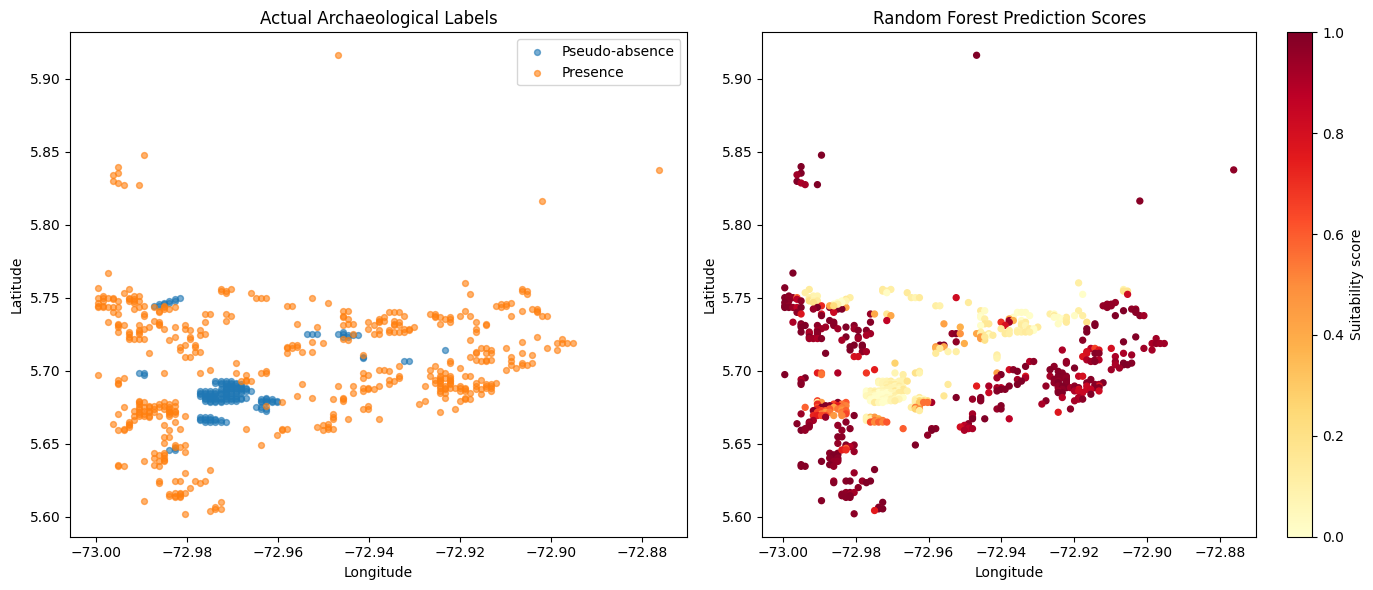

In [ ]:

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Actual archaeological labels
presence = map_data["type"] == "presence"

axes[0].scatter(
    map_data.loc[~presence, "x"],
    map_data.loc[~presence, "y"],
    s=18,
    alpha=0.6,
    label="Pseudo-absence"
)

axes[0].scatter(
    map_data.loc[presence, "x"],
    map_data.loc[presence, "y"],
    s=18,
    alpha=0.6,
    label="Presence"
)

axes[0].set_title("Actual Archaeological Labels")
axes[0].set_xlabel("Longitude")
axes[0].set_ylabel("Latitude")
axes[0].legend()

# Random Forest predictions
scatter = axes[1].scatter(
    map_data["x"],
    map_data["y"],
    c=map_data["suitability_score"],
    cmap="YlOrRd",
    s=18,
    vmin=0,
    vmax=1
)

axes[1].set_title("Random Forest Prediction Scores")
axes[1].set_xlabel("Longitude")
axes[1].set_ylabel("Latitude")

fig.colorbar(
    scatter,
    ax=axes[1],
    label="Suitability score"
)

plt.tight_layout()
plt.show()
